<a href="https://colab.research.google.com/github/europecodingschool/ECS---VB---YZ---08.26/blob/main/VB_YZ_Ders_23_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

In [6]:
adres = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
urllib.request.urlretrieve(adres + "fruits.jpg", "fruits.jpg")
urllib.request.urlretrieve(adres + "smarties.png", "smarties.png")

print("OpenCV sürümü", cv2.__version__)




OpenCV sürümü 4.14.0


In [9]:
#FOTOĞRAF DÜZENLEYİCİ

meyve = cv2.imread("fruits.jpg") # Resmi çağırma.

print("Şekli:", meyve.shape)
print("Veri Tİpi:", meyve.dtype)
print("Sol üst piksel:", meyve[0,0])

Şekli: (480, 512, 3)
Veri Tİpi: uint8
Sol üst piksel: [ 13  62 130]


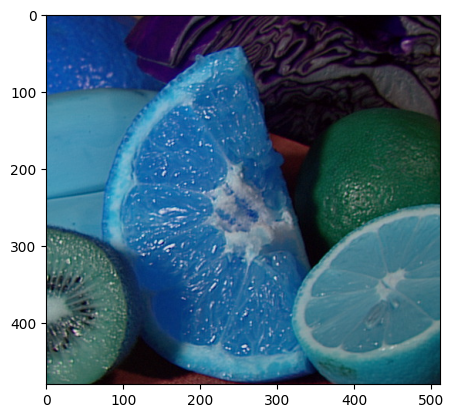

In [11]:
plt.imshow(meyve)
plt.show() #RGB normalde renk kayıt sırası fakat opencv renkleri BGR formatında kaydediyor. O yüzden gösterimden önce dönüştürmek gerekiyor.

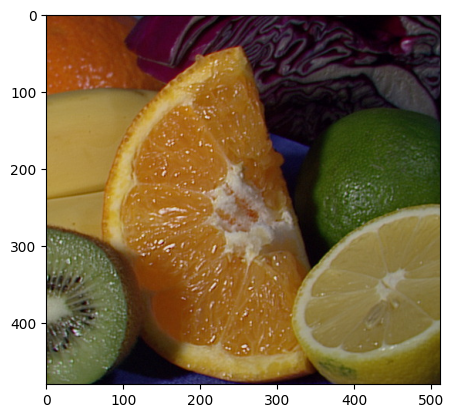

In [13]:
meyve_rgb = cv2.cvtColor(meyve, cv2.COLOR_BGR2RGB) # Matplotlib RGB rengi beklediği için çizmeden önce çeviriyoruz. Çevirmezsek portakal mavi göründü.
plt.imshow(meyve_rgb)

gri şekil: (480, 512)


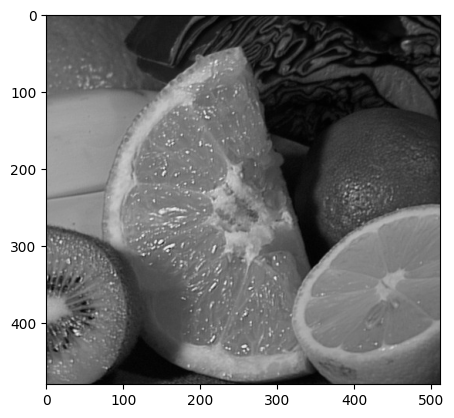

In [17]:
meyve_gri = cv2.cvtColor(meyve, cv2.COLOR_BGR2GRAY) # resmi griye dönüştürdük. Tek kanallı hale gelmesini istedik.
plt.imshow(meyve_gri, cmap="gray") # Tek kanallı gri bir resme dönüştü. Teyit ediyoruz.

print("gri şekil:", meyve_gri.shape)

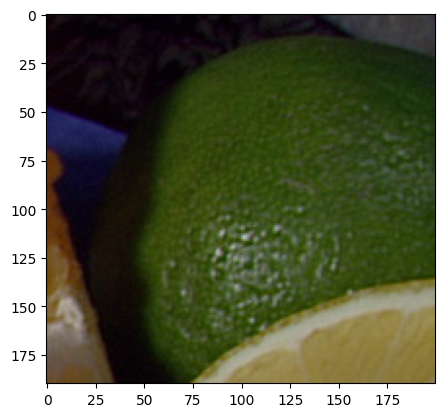

In [20]:
#Kırpma ve Boyutlandırma

limon = meyve_rgb[110:300, 300:500] # kırpma işlemi. önce satırlar sonra sütınlar. Önce dikeyde 110 ile 300 arasını sonra yatayda 300 ile 500 arasını dilimledik.
plt.imshow(limon)

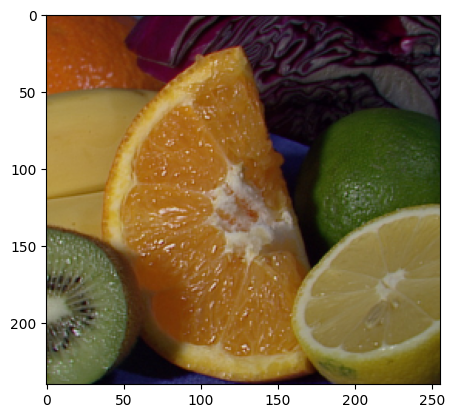

In [23]:
kucuk = cv2.resize(meyve_rgb, (256,240))
plt.imshow(kucuk)
#

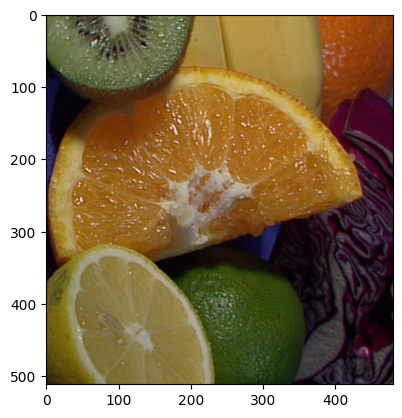

In [26]:
#DÖNDÜRME

dondur = cv2.rotate(meyve_rgb, cv2.ROTATE_90_CLOCKWISE) # saat yönünde 90 derece döndürme.
plt.imshow(dondur)

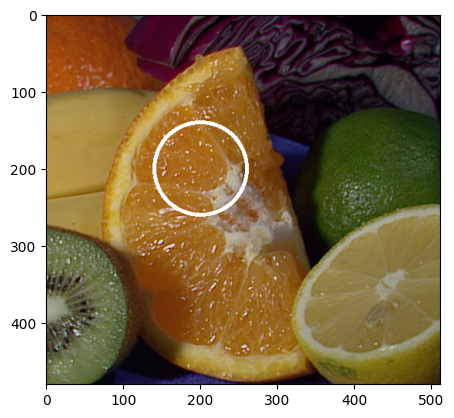

In [29]:
#Resmin üzerine nesne çizme

kart = meyve_rgb.copy()

cv2.circle(kart, (200,200), 60, (255,255,255), 3) #resmin üzerine yuvarlak çizme. Sırası ile parametreler: Merkez nerede olacak > Yarıçap > Renk > Kalınlık

plt.imshow(kart)
#

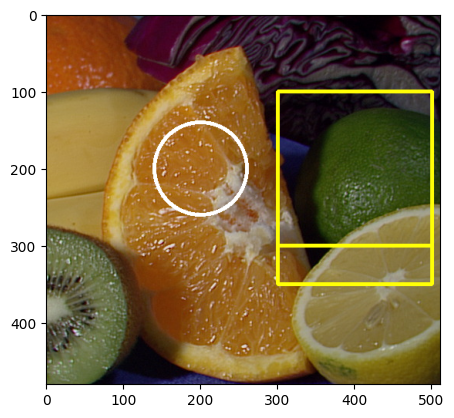

In [33]:
cv2.rectangle(kart, (300,100), (500,300), (255,255,6), 3) # diktörgen çizme. Sırası ile parametreler: Sol üst köşe > sağ alt köşe > renk > kalınlık
plt.imshow(kart)
#

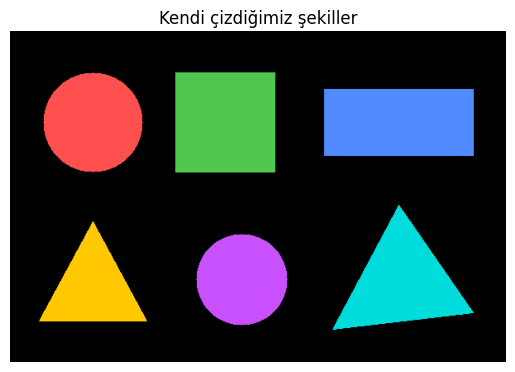

In [36]:
tuval = np.zeros((400, 600, 3), np.uint8)
cv2.circle(tuval, (100, 110), 60, (255, 80, 80), -1)
cv2.rectangle(tuval, (200, 50), (320, 170), (80, 200, 80), -1)
cv2.rectangle(tuval, (380, 70), (560, 150), (80, 140, 255), -1)
ucgen1 = np.array([[100, 230], [35, 350], [165, 350]], np.int32)
cv2.fillPoly(tuval, [ucgen1], (255, 200, 0))
cv2.circle(tuval, (280, 300), 55, (200, 80, 255), -1)
ucgen2 = np.array([[470, 210], [390, 360], [560, 340]], np.int32)
cv2.fillPoly(tuval, [ucgen2], (0, 220, 220))
plt.imshow(tuval)
plt.title("Kendi çizdiğimiz şekiller")
plt.axis("off")
plt.show()

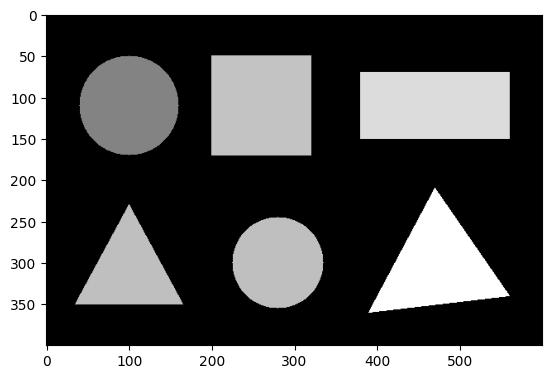

In [38]:
#Griye Çevirme
tuval_gri = cv2.cvtColor(tuval, cv2.COLOR_BGR2GRAY)
plt.imshow(tuval_gri, cmap="gray")
#



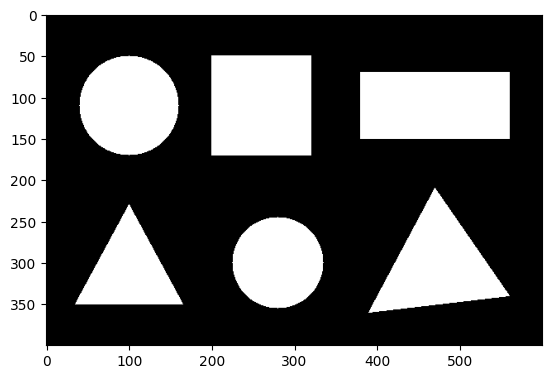

In [39]:
# MASKE OLUŞTURMA

esik, sekil_maske = cv2.threshold(tuval_gri, 0, 255, cv2.THRESH_BINARY)
plt.imshow(sekil_maske, cmap="gray")
#